In [5]:
import pandas as pd
import numpy as np
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import joblib

# Read parquet file
df = pd.read_parquet("../data/staging_imdb.parquet")


In [3]:
df

,id,embed
0,1,"[-0.032867431640625, 0.0066070556640625, -0.01..."
1,2,"[-0.046600341796875, 0.0458984375, -0.08984375..."
2,3,"[-0.034027099609375, 0.023284912109375, -0.028..."
3,4,"[-0.056488037109375, 0.021148681640625, -0.065..."
4,5,"[-0.00942230224609375, 0.050628662109375, -0.0..."
...,...,...
995,996,"[-0.06719970703125, 0.009063720703125, -0.0455..."
996,997,"[-0.032470703125, 0.003902435302734375, -0.012..."
997,998,"[-0.05047607421875, 0.056060791015625, 0.00191..."
998,999,"[-0.070556640625, 0.031280517578125, 0.0100402..."


Bentuk Matriks: (1000, 1536)


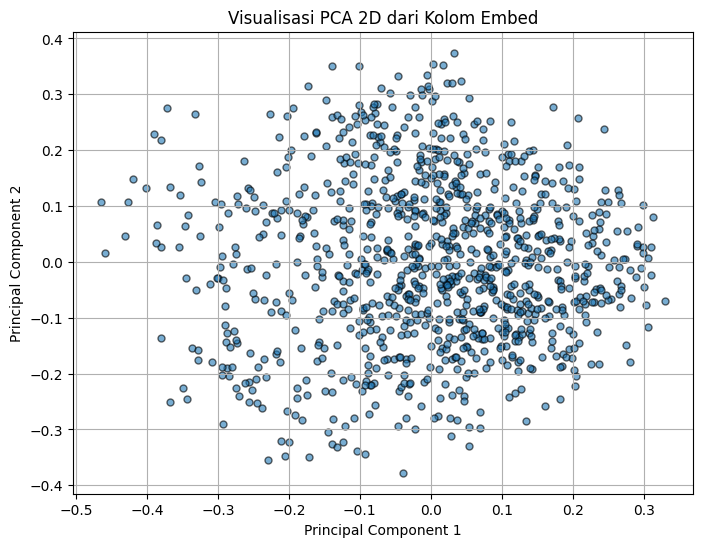

In [9]:

# 1. Konversi kolom 'embed' menjadi matriks 2D NumPy (N x D)
X = np.vstack(df['embed'].values)

print(f"Bentuk Matriks: {X.shape}") 
# Contoh output: (998, 384) atau (998, 768)

# 2. Jalankan PCA 2D
pca = PCA(n_components=2)
X_2d = pca.fit_transform(X)

# 3. Masukkan hasil PC1 & PC2 kembali ke DataFrame (opsional)
df['PC1'] = X_2d[:, 0]
df['PC2'] = X_2d[:, 1]

# 4. Visualisasi Scatter Plot 2D
plt.figure(figsize=(8, 6))
plt.scatter(df['PC1'], df['PC2'], alpha=0.6, edgecolors='k', s=25)
plt.title('Visualisasi PCA 2D dari Kolom Embed')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.grid(True)
plt.show()

In [10]:
df

,id,embed,PC1,PC2
0,1,"[-0.032867431640625, 0.0066070556640625, -0.01...",0.103311,-0.079614
1,2,"[-0.046600341796875, 0.0458984375, -0.08984375...",0.201869,-0.072180
2,3,"[-0.034027099609375, 0.023284912109375, -0.028...",0.019826,-0.218785
3,4,"[-0.056488037109375, 0.021148681640625, -0.065...",0.150769,-0.063211
4,5,"[-0.00942230224609375, 0.050628662109375, -0.0...",0.262769,-0.033749
...,...,...,...,...
995,996,"[-0.06719970703125, 0.009063720703125, -0.0455...",0.069334,0.078862
996,997,"[-0.032470703125, 0.003902435302734375, -0.012...",0.127689,-0.120355
997,998,"[-0.05047607421875, 0.056060791015625, 0.00191...",0.222183,0.030160
998,999,"[-0.070556640625, 0.031280517578125, 0.0100402...",0.169961,0.040189


In [11]:
model_path = "pca_model.joblib"
joblib.dump(pca, model_path)

['pca_model.joblib']

In [13]:
import sqlite3

# 1. Path ke database (relatif dari folder pca)
db_path = "../data/database.db"
conn = sqlite3.connect(db_path)
cursor = conn.cursor()

# 2. Tambahkan kolom PC1 dan PC2 ke tabel imdb_movies (jika belum ada)
for col in ["PC1", "PC2"]:
    try:
        cursor.execute(f"ALTER TABLE imdb_movies ADD COLUMN {col} REAL;")
        print(f"Kolom {col} berhasil ditambahkan.")
    except sqlite3.OperationalError:
        # Mengabaikan error jika kolom sudah ada sebelumnya
        pass

# 3. Update nilai PC1 dan PC2 berdasarkan id
# Parameter tuple: (nilai_PC1, nilai_PC2, id)
records = df[['PC1', 'PC2', 'id']].to_numpy().tolist()

cursor.executemany("""
    UPDATE imdb_movies 
    SET PC1 = ?, PC2 = ? 
    WHERE id = ?
""", records)

# 4. Commit perubahan dan tutup koneksi
conn.commit()
conn.close()

print(f"Berhasil memperbarui PC1 dan PC2 pada {len(records)} baris di tabel 'imdb_movies'!")

Kolom PC1 berhasil ditambahkan.
Kolom PC2 berhasil ditambahkan.
Berhasil memperbarui PC1 dan PC2 pada 1000 baris di tabel 'imdb_movies'!
